# Fase 2: Comprensión de los Datos / Data Understanding
La fase de comprensión de datos comienza con una recopilación inicial de datos y continúacon actividades para familiarizarse con los datos, identificar problemas de calidad de losdatos, descubrir los primeros conocimientos sobre los datos o detectar subconjuntos interesantes para formular hipótesis sobre información oculta.
* Establecé una metodología de adquisición de los datos para el negocio.
* Contemplá en la adquisición de datos una alternativa donde debas construir el setde datos.
* Identificá los distintos problemas o desafíos con los datos (datos faltantes, ruidos,etc) que puedan afectar a su calidad.
* Enumerá las distintas fases, tareas generales, tareas específicas e instancias del proceso que incluirás como estrategia para aplicar la metodología

## 2.1. Fuente y licencia de uso
Como fuente principal de datos se utiliza el conjunto de datos públicos correspondiente al Adjunto IV, de la Secretaría de Energía de la Nación, el cual registra las operaciones de fractura hidráulica llevadas a cabo en pozos de hidrocarburos no convencionales en Argentina.

El conjunto de datos cuenta con una ficha descriptiva en el portal oficial cuya última edición data del 5 de septiembre de 2024; no obstante, el recurso en formato CSV se mantiene con actualización periódica automatizada (declarada con frecuencia diaria), reflejando las declaraciones juradas y operaciones más recientes cargadas por las operadoras.

Se distribuye bajo la licencia internacional Creative Commons Attribution 4.0 (CC BY 4.0), que permite la descarga, reutilización, adaptación y distribución libre de la información para fines académicos y de investigación; con el único requisito de brindar el reconocimiento y citación adecuada a la fuente oficial.


## 2.2. Metodología de adquisición de los datos

Como el CSV se actualiza diariamente, cada descarga puede tener una cantidad distinta de registros. Para que todas las fases trabajen sobre los mismos datos, la adquisición sigue estos pasos:

1. **Identificar la fuente.** Se ubica el recurso oficial en el portal de datos abiertos de Energía y se revisan su ficha y su licencia ([datos.gob.ar — Adjunto IV](https://datos.gob.ar/dataset/datos-de-fractura-de-pozos-adjunto-iv)).
2. **Descargar.** Se descarga el CSV desde la URL oficial del recurso mediante la función `descargar_dataset()` de `comun.py`.
3. **Congelar la versión.** Se guarda una única copia en `data/` y se versiona en el repositorio. Todas las fases leen ese mismo archivo y no se vuelve a descargar durante el análisis. La versión queda identificada por el commit del CSV y por su fecha máxima de carga (`fecha_data`).
4. **Verificar la estructura.** Se controlan la cantidad de filas y columnas, los nombres de las columnas y que las fechas se puedan convertir (sección 2.6.1).
5. **Documentar.** Se registran la fecha de corte, la cantidad de registros y los problemas de calidad encontrados (secciones 2.6 y 2.7).
6. **Actualizar a futuro.** Para incorporar datos nuevos, se repiten los pasos 2 a 5 y se vuelven a ejecutar todas las fases, según el plan de mantenimiento de la Fase 6.

---
## 2.3. Alternativa: construcción propia del dataset

Si el Adjunto IV dejara de publicarse, cambiara su estructura o no alcanzara para responder la pregunta de estudio, el dataset se podría construir combinando otras fuentes:

- **Otros datasets de la Secretaría de Energía** (padrón de pozos, producción por pozo - Capítulo IV): aportan la ubicación, el tipo de pozo y la producción posterior a la fractura. Se descargan desde datos.gob.ar y se unen por `idpozo`.

- **Informes y datos provinciales** (por ejemplo, de los organismos de energía y de recursos hídricos de Neuquén): aportan los volúmenes de agua autorizados y la fuente de captación. Se obtienen descargando informes públicos o mediante un pedido de acceso a la información pública.

- **Formulario propio dirigido a operadoras o especialistas.**: permite relevar variables que hoy no existen en la fuente, como el fluido usado o la reutilización de agua. Se diseñaría como un formulario estructurado con las mismas definiciones y unidades del Adjunto IV.

Además se debería definir un diccionario de datos común (nombres, unidades y tipos), unir las fuentes por identificador de pozo y fecha, y controlar duplicados y diferencias entre fuentes antes de continuar con la Fase 3.

## 2.4. Carga del dataset

In [19]:
# @title Imports
# @title 2.4.1 Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

from comun import RUTA_DATOS, leer_dataframe_con_fechas # , descargar_dataset


In [20]:
# @title 2.4.2. Descarga de archivo (sólo para actualizar)
# descargar_dataset()

In [21]:
# @title 2.4.3. Carga de datos

# leer_dataframe_con_fechas() lee el .CSV, convierte las fechas y agrega columnas derivadas
df_datos_energia = leer_dataframe_con_fechas()

# Columnas tal como vienen en el archivo original (sin las derivadas)
columnas_originales = pd.read_csv(RUTA_DATOS, nrows=0).columns.tolist()

print(f"Registros: {len(df_datos_energia):,}")
print(f"Columnas originales: {len(columnas_originales)}")
print(f"Pozos distintos: {df_datos_energia['idpozo'].nunique():,}")
print(f"Fecha de carga más reciente (versión del archivo): {df_datos_energia['fecha_data'].max():%d/%m/%Y}")

df_datos_energia[columnas_originales].head()

Registros: 4,983
Columnas originales: 30
Pozos distintos: 4,739
Fecha de carga más reciente (versión del archivo): 07/10/2026


,id_base_fractura_adjiv,idpozo,sigla,cuenca,areapermisoconcesion,yacimiento,formacion_productiva,tipo_reservorio,subtipo_reservorio,longitud_rama_horizontal_m,...,fecha_data,anio_if,mes_if,anio_ff,mes_ff,anio_carga,mes_carga,empresa_informante,mes,anio
0,30,159910,APS.Nq.ADC.xp-1033,NEUQUINA,AGUA DEL CAJON,AGUA DEL CAJON,los molles,NO CONVENCIONAL,SHALE,0.0,...,2019-06-14 17:13:03.682790,2019,4,2019,4,2019,6,CAPEX S.A.,4,2019
1,31,159910,APS.Nq.ADC.xp-1033,NEUQUINA,AGUA DEL CAJON,AGUA DEL CAJON,los molles,NO CONVENCIONAL,SHALE,0.0,...,2019-06-14 17:14:19.179874,2018,11,2018,11,2019,6,CAPEX S.A.,11,2018
2,37,159219,YPF.Nq.AdlA-1001(h),NEUQUINA,AGUADA DE LA ARENA,AGUADA DE LA ARENA,vaca muerta,NO CONVENCIONAL,SHALE,1437.3,...,2019-06-27 13:46:21.149350,2017,11,2017,12,2019,6,YPF S.A.,11,2017
3,38,159220,YPF.Nq.AdlA-1002(h),NEUQUINA,AGUADA DE LA ARENA,AGUADA DE LA ARENA,vaca muerta,NO CONVENCIONAL,SHALE,1518.3,...,2019-06-27 13:46:21.149350,2017,11,2017,12,2019,6,YPF S.A.,11,2017
4,39,159221,YPF.Nq.AdlA-1003(h),NEUQUINA,AGUADA DE LA ARENA,AGUADA DE LA ARENA,vaca muerta,NO CONVENCIONAL,SHALE,1482.3,...,2019-06-27 13:46:21.149350,2017,11,2017,12,2019,6,YPF S.A.,11,2017


## 2.5. Análisis exploratorio de los datos (EDA)
El Análisis Exploratorio de Datos (EDA) permite obtener una primera comprensión del comportamiento de las variables y su relación con la variable objetivo. Esta etapa es fundamental antes de construir modelos de machine learning, ya que permite detectar problemas en los datos y entender qué variables pueden tener mayor poder explicativo.

#### 2.5.1. Análisis de la estructura del dataset

En primer lugar, se analiza:

* Cantidad de filas (observaciones)
* Cantidad de columnas (variables)
* Tipos de datos de cada variable
* Identificación de la variable objetivo
* Identificación de variables numéricas y categóricas

Este análisis permite entender la dimensionalidad del problema y el tipo de modelo que se deberá utilizar posteriormente.

In [22]:
# @title Cantidad de filas y columnas
num_filas, num_columnas = df_datos_energia.shape
print(f"El Dataset tiene {num_filas} filas y {num_columnas} columnas.")

El Dataset tiene 4983 filas y 43 columnas.


In [23]:
# @title Tipos de datos de cada variable
def tipo_general(serie):
    if pd.api.types.is_datetime64_any_dtype(serie):
        return "Fecha"
    if pd.api.types.is_numeric_dtype(serie):
        return "Numérica"
    return "Categórica / texto"


df_tipos = pd.DataFrame(
    {
        "Variable": columnas_originales,
        "Tipo general": [tipo_general(df_datos_energia[col]) for col in columnas_originales],
        "Valores distintos": [df_datos_energia[col].nunique() for col in columnas_originales],
        "Faltantes": [df_datos_energia[col].isna().sum() for col in columnas_originales],
    }
)
display(df_tipos.sort_values(["Tipo general", "Variable"]).reset_index(drop=True))

,Variable,Tipo general,Valores distintos,Faltantes
0,areapermisoconcesion,Categórica / texto,105,0
1,cuenca,Categórica / texto,3,0
2,empresa_informante,Categórica / texto,23,0
3,formacion_productiva,Categórica / texto,28,0
4,sigla,Categórica / texto,4697,0
5,subtipo_reservorio,Categórica / texto,2,973
6,tipo_reservorio,Categórica / texto,3,35
7,tipo_terminacion,Categórica / texto,5,0
8,yacimiento,Categórica / texto,140,0
9,fecha_data,Fecha,979,0


### Diccionario de datos resumido

Cada registro representa **una operación de fractura informada para un pozo**. Un mismo pozo puede tener más de una operación.

| Grupo | Variables | Descripción |
|---|---|---|
| Identificación | `id_base_fractura_adjiv`, `idpozo`, `sigla` | Identificador del registro, del pozo y su nombre. |
| Ubicación | `cuenca`, `areapermisoconcesion`, `yacimiento` | Cuenca sedimentaria, área de concesión y yacimiento. |
| Reservorio | `formacion_productiva`, `tipo_reservorio`, `subtipo_reservorio` | Formación geológica, convencional / no convencional y shale / tight. |
| Pozo y operación | `longitud_rama_horizontal_m`, `cantidad_fracturas`, `tipo_terminacion` | Largo de la rama horizontal (m), etapas de fractura y técnica de terminación. |
| Insumos | `agua_inyectada_m3`, `arena_bombeada_nacional_tn`, `arena_bombeada_importada_tn`, `co2_inyectado_m3` | Volúmenes de agua (m³), arena (t) y CO₂ (m³). |
| Equipos | `presion_maxima_psi`, `potencia_equipos_fractura_hp` | Presión máxima (psi) y potencia de los equipos (hp). |
| Fechas | `fecha_inicio_fractura`, `fecha_fin_fractura`, `fecha_data` y sus desagregados (`anio_if`, `mes_if`, `anio_ff`, `mes_ff`, `anio_carga`, `mes_carga`, `anio`, `mes`) | Inicio y fin de la operación y fecha de carga de la declaración. |
| Administrativa | `empresa_informante` | Operadora que declara la fractura. |

**Variable objetivo:** `agua_inyectada_m3`, volumen de agua inyectado en la operación (cuantitativa continua, en m³). Al ser numérica, el problema de la Fase 4 se plantea como **regresión**.

### 2.5.2 Análisis estadístico descriptivo

Se realiza un análisis estadístico descriptivo de las variables numéricas, calculando:

* Media
* Mediana
* Desvío estándar
* Valor mínimo
* Valor máximo
* Cuartiles (Q1, Q2, Q3)

Este análisis permite entender la dispersión de los datos, detectar posibles outliers y analizar si las variables presentan comportamientos muy diferentes entre sí.

In [24]:
# @title Estadística descriptiva de las variables numéricas
excluir = ["id_base_fractura_adjiv", "idpozo",          
           "anio_if", "mes_if", "anio_ff", "mes_ff",     
           "anio_carga", "mes_carga", "mes", "anio"]

num_cols = [
    c for c in columnas_originales
    if pd.api.types.is_numeric_dtype(df_datos_energia[c]) and c not in excluir
]
# Se suma la duración de la operación, ya expresada en días (numérica)
num_cols.append("duracion_fractura_dias")


def estadisticos(s):
    s = s.dropna()
    q1, q2, q3 = s.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    media, desvio = s.mean(), s.std()
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({
        "conteo": s.count(),
        "media": media,
        "varianza": s.var(),
        "desvio": desvio,
        "moda": s.mode().iloc[0],
        "minimo": s.min(),
        "Q1": q1,
        "mediana (Q2)": q2,
        "Q3": q3,
        "maximo": s.max(),
        "rango": s.max() - s.min(),
        "lim_inf": lim_inf,
        "lim_sup": lim_sup,
        "CV (%)": desvio / media * 100 if media != 0 else np.nan,
    })


resumen = df_datos_energia[num_cols].apply(estadisticos).T.round(2)

with pd.option_context("display.max_columns", None, "display.width", 250,
                       "display.float_format", lambda x: f"{x:,.2f}"):
    display(resumen)


,conteo,media,varianza,desvio,moda,minimo,Q1,mediana (Q2),Q3,maximo,rango,lim_inf,lim_sup,CV (%)
longitud_rama_horizontal_m,"4,983.00","1,371.28","1,882,484.02","1,372.04",0.00,0.00,0.00,"1,405.90","2,608.34","5,114.11","5,114.11","-3,912.51","6,520.85",100.05
cantidad_fracturas,"4,983.00",23.53,460.44,21.46,1.00,1.00,4.00,18.00,43.00,105.00,104.00,-54.50,101.50,91.19
arena_bombeada_nacional_tn,"4,983.00","4,860.38","27,490,511.45","5,243.14",0.00,0.00,0.00,"2,922.12","9,696.61","20,834.00","20,834.00","-14,544.92","24,241.52",107.88
arena_bombeada_importada_tn,"4,983.00",339.60,"3,057,117.40","1,748.46",0.00,0.00,0.00,7.00,363.65,"80,652.00","80,652.00",-545.47,909.12,514.86
agua_inyectada_m3,"4,983.00","33,403.52","1,357,825,049.90","36,848.68",0.00,0.00,525.14,"21,387.20","62,616.87","537,184.60","537,184.60","-92,612.45","155,754.46",110.31
co2_inyectado_m3,"4,983.00",5.37,"1,375.52",37.09,0.00,0.00,0.00,0.00,0.00,560.00,560.00,0.00,0.00,691.25
presion_maxima_psi,"4,983.00","9,329.17","39,766,619.61","6,306.08",0.00,0.00,"6,900.50","11,000.00","11,775.00","209,640.56","209,640.56",-411.26,"19,086.76",67.60
potencia_equipos_fractura_hp,"4,932.00","20,938.81","258,514,346.20","16,078.38","40,000.00",0.00,"2,376.50","22,299.24","34,000.00","236,451.00","236,451.00","-45,058.75","81,435.25",76.79
duracion_fractura_dias,"4,983.00",19.05,"2,551.61",50.51,0.00,-362.00,3.00,13.00,25.00,"1,831.00","2,193.00",-30.00,58.00,265.16


### 2.5.3 Análisis de valores faltantes

En esta etapa se verifica la existencia de valores faltantes en el dataset. La presencia de valores nulos puede afectar el rendimiento de los modelos de machine learning, por lo que es importante detectarlos y definir una estrategia para tratarlos (eliminación de registros, imputación, etc.).

En caso de que el dataset no presente valores faltantes, esto representa una ventaja, ya que no será necesario realizar procesos de imputación.

Se analizan tres tipos de faltantes:

* **Explícitos:** celdas vacías (`NaN`) en el archivo.
* **Estructurales:** vacíos que no son un error, porque la variable no aplica a ese registro.
* **Ocultos:** valores cargados que en realidad representan un dato ausente (ceros físicamente imposibles o categorías como "NO DISCRIMINADO").

In [25]:
# @title Faltantes explícitos por variable
faltantes = pd.DataFrame({
    "faltantes": df_datos_energia[columnas_originales].isna().sum(),
    "% faltantes": (df_datos_energia[columnas_originales].isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes["faltantes"] > 0].sort_values("faltantes", ascending=False)

print(f"Variables con faltantes: {len(faltantes)} de {len(columnas_originales)}")
print(f"Registros con al menos un faltante: {df_datos_energia[columnas_originales].isna().any(axis=1).sum():,}")
display(faltantes)

Variables con faltantes: 3 de 30
Registros con al menos un faltante: 1,008


,faltantes,% faltantes
subtipo_reservorio,973,19.53
potencia_equipos_fractura_hp,51,1.02
tipo_reservorio,35,0.70


In [26]:
# @title Faltantes estructurales: subtipo de reservorio según tipo
# El subtipo (shale / tight) sólo se define para reservorios no convencionales
display(pd.crosstab(
    df_datos_energia["tipo_reservorio"].fillna("(vacío)"),
    df_datos_energia["subtipo_reservorio"].fillna("(vacío)"),
    margins=True, margins_name="Total",
))

subtipo_reservorio,(vacío),SHALE,TIGHT,Total
tipo_reservorio,,,,
(vacío),35,0,0,35
CONVENCIONAL,932,0,0,932
NO CONVENCIONAL,5,3107,903,4015
NO DISCRIMINADO,1,0,0,1
Total,973,3107,903,4983


In [27]:
# @title Patrón de los faltantes de potencia
nulos_potencia = df_datos_energia[df_datos_energia["potencia_equipos_fractura_hp"].isna()]

print("Empresa informante:")
display(nulos_potencia["empresa_informante"].value_counts().to_frame("registros"))
print("Año de inicio de la fractura:")
display(nulos_potencia["anio_if"].value_counts().sort_index().to_frame("registros"))

Empresa informante:


,registros
empresa_informante,
OILSTONE ENERGIA S.A.,51


Año de inicio de la fractura:


,registros
anio_if,
2010,3
2011,20
2012,6
2013,11
2014,7
2016,1
2018,3


In [28]:
# @title Faltantes ocultos
# Variables en las que un 0 no es físicamente posible si hubo una fractura
vars_sin_cero = ["agua_inyectada_m3", "presion_maxima_psi", "potencia_equipos_fractura_hp"]

ocultos = pd.DataFrame({
    "ceros": (df_datos_energia[vars_sin_cero] == 0).sum(),
    "% ceros": ((df_datos_energia[vars_sin_cero] == 0).mean() * 100).round(2),
})
display(ocultos)

no_discriminado = (df_datos_energia["tipo_reservorio"] == "NO DISCRIMINADO").sum()
print(f"tipo_reservorio = 'NO DISCRIMINADO': {no_discriminado} registro(s)")

,ceros,% ceros
agua_inyectada_m3,305,6.12
presion_maxima_psi,78,1.57
potencia_equipos_fractura_hp,154,3.09


tipo_reservorio = 'NO DISCRIMINADO': 1 registro(s)


**Resultados del análisis de faltantes**

* **Faltantes explícitos:** sólo 3 de las 30 variables tienen celdas vacías (`subtipo_reservorio`, `potencia_equipos_fractura_hp` y `tipo_reservorio`).

* **`subtipo_reservorio` es mayormente estructural:** 932 de los 973 vacíos corresponden a reservorios convencionales, donde la clasificación shale / tight no aplica. No deben imputarse, se pueden recodificar como "NO APLICA". Los faltantes reales son sólo 5 no convencionales sin subtipo, los 35 sin tipo y 1 "NO DISCRIMINADO".

* **Los vacíos de potencia no son aleatorios:** los 51 provienen de una única operadora (Oilstone Energía S.A.) y casi todos (47) de fracturas realizadas entre 2010 y 2014. Es un problema de carga de una empresa en un período, no un faltante al azar, por lo que imputar con la media global podría sesgar la variable.

* **Hay faltantes ocultos en forma de ceros:** 305 registros tienen `agua_inyectada_m3 = 0`, 154 tienen potencia 0 y 78 presión 0.
Una fractura hidráulica no puede realizarse sin agua, presión ni potencia, así que estos ceros deben tratarse como datos ausentes. Para la variable objetivo esto es clave ya que esos registros no pueden usarse para entrenar el modelo.

* **Ceros que sí son válidos:** en `longitud_rama_horizontal_m` el 0 indica un pozo vertical, y en `co2_inyectado_m3` y en las arenas indica que no se usó ese insumo. Estos ceros no se consideran faltantes.

### 2.5.4 Análisis de la distribución de las variables

Se analizan las distribuciones de las variables numéricas mediante histogramas y boxplots. Este análisis permite:

* Analizar la dispersión de los datos.
* Identificar si las variables presentan distribución normal o sesgada.
* Detectar outliers.
* Comparar la distribución de las variables entre las clases Cammeo y Osmancik.

Este punto es muy importante, ya que si las variables presentan diferencias significativas entre las clases, entonces serán buenas variables predictoras para el modelo de clasificación.

#### Prueba de hipótesis de normalidad

Antes de detectar outliers es necesario determinar si cada variable sigue una distribución normal, ya que influye en el método a utilizar.


Para cada variable numérica se plantea la siguiente prueba de hipótesis:

* **H₀ (hipótesis nula):** la variable sigue una distribución normal.
* **Hₐ (hipótesis alternativa):** la variable no sigue una distribución normal.

**Nivel de significancia:** α = 0,05. 

In [29]:
# @title Test de normalidad por variable
df_dist = df_datos_energia[num_cols].copy()
vars_sin_cero = ["agua_inyectada_m3", "presion_maxima_psi", "potencia_equipos_fractura_hp"]
df_dist[vars_sin_cero] = df_dist[vars_sin_cero].replace(0, np.nan)


def test_normalidad(s, alfa=0.05):
    s = s.dropna()
    n = len(s)

    if n < 50:
        test = "Shapiro-Wilk"
        estadistico, p_value = stats.shapiro(s)
    else:
        test = "Kolmogorov-Smirnov (Lilliefors)"
        res = stats.goodness_of_fit(stats.norm, s, statistic="ks",
                                    n_mc_samples=999, random_state=42)
        estadistico, p_value = res.statistic, res.pvalue

    return pd.Series({
        "estadístico": round(estadistico, 4),
        "p-valor": round(p_value, 4),
        "asimetría": round(s.skew(), 2),
        "curtosis": round(s.kurt(), 2),
        "decisión (α = 0,05)": "Se rechaza H0" if p_value < alfa else "No se rechaza H0"
    })


resultados_normalidad = df_dist.apply(test_normalidad).T
display(resultados_normalidad)

,estadístico,p-valor,asimetría,curtosis,"decisión (α = 0,05)"
longitud_rama_horizontal_m,0.2779,0.001,0.27,-1.47,Se rechaza H0
cantidad_fracturas,0.1923,0.001,0.56,-0.83,Se rechaza H0
arena_bombeada_nacional_tn,0.2531,0.001,0.53,-1.16,Se rechaza H0
arena_bombeada_importada_tn,0.423,0.001,36.93,1638.5,Se rechaza H0
agua_inyectada_m3,0.2022,0.001,2.09,20.85,Se rechaza H0
co2_inyectado_m3,0.5256,0.001,8.82,89.04,Se rechaza H0
presion_maxima_psi,0.2612,0.001,16.44,420.94,Se rechaza H0
potencia_equipos_fractura_hp,0.1355,0.001,1.31,16.8,Se rechaza H0
duracion_fractura_dias,0.3448,0.001,12.78,371.43,Se rechaza H0


**Conclusión**

Para las 9 variables analizadas el p-value es menor que α = 0.05, por lo que **se rechaza H₀ en todos los casos**, con un 95 % de confianza, se afirma que ninguna variable sigue una distribución normal. Se utiliza el **método no paramétrico del rango intercuartílico (IQR)** para el cálculo de outliers.

Además podemos observar:
* Asimetría positiva fuerte y curtosis muy altas en `arena_bombeada_importada_tn`, `presion_maxima_psi`, `duracion_fractura_dias` y `co2_inyectado_m3`. Son colas largas a la derecha con valores extremos.
* Asimetría moderada en `agua_inyectada_m3` y `potencia_equipos_fractura_hp`.
* Curtosis negativas (distribuciones aplanadas) en `longitud_rama_horizontal_m`, `cantidad_fracturas` y `arena_bombeada_nacional_tn`. Esto refleja la mezcla de pozos verticales y horizontales.

#### Distribución y dispersión de las variables

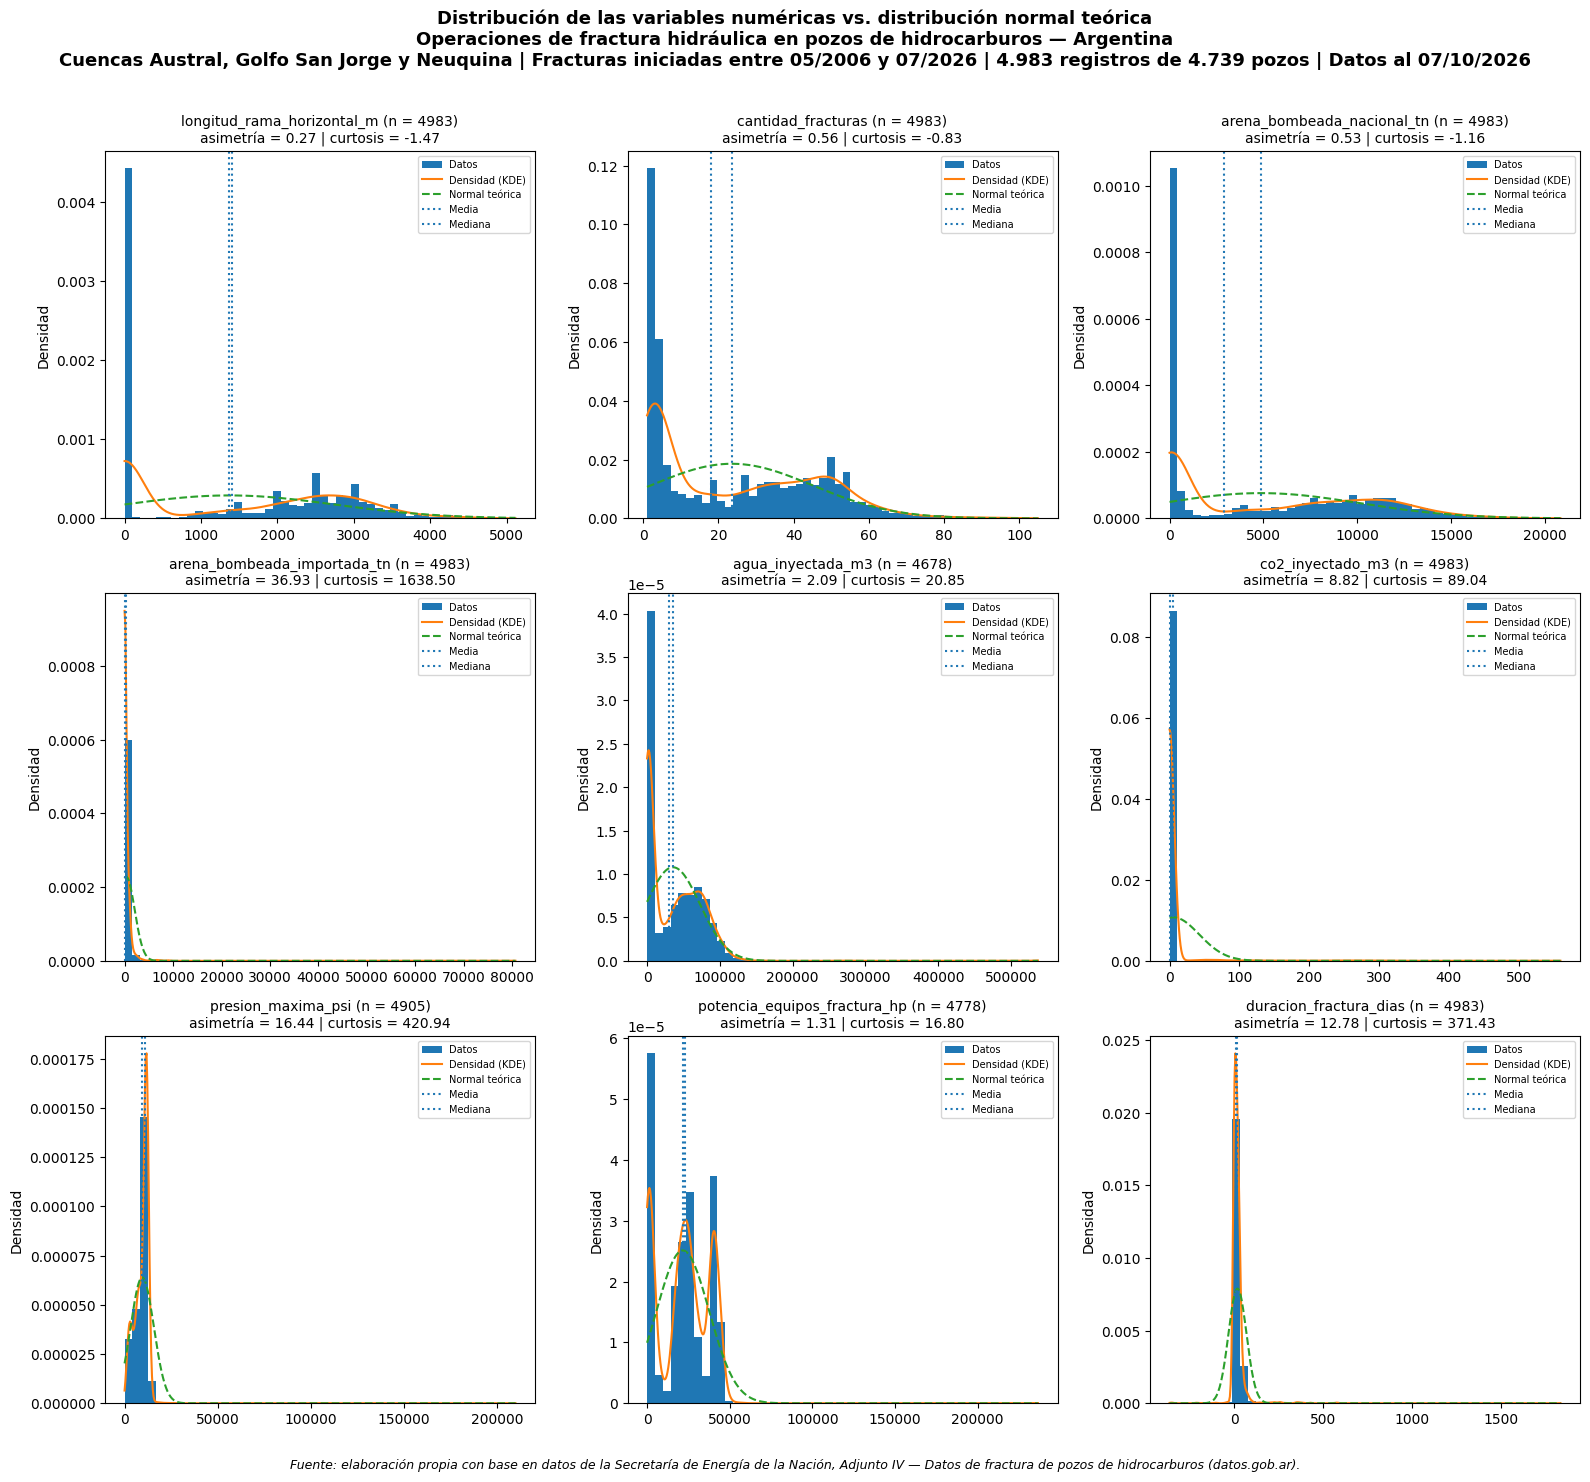

In [35]:
#@title Histogramas con curva de densidad vs. normal teórica
n_cols = 3
n_filas = int(np.ceil(len(num_cols) / n_cols))
fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 4.5 * n_filas + 1.5))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    s = df_dist[col].dropna()
    x = np.linspace(s.min(), s.max(), 500)

    ax.hist(s, bins=50, density=True, label="Datos")
    ax.plot(x, stats.gaussian_kde(s)(x), label="Densidad (KDE)")
    ax.plot(x, stats.norm.pdf(x, s.mean(), s.std()), linestyle="--", label="Normal teórica")
    ax.axvline(s.mean(), linestyle=":", label="Media")
    ax.axvline(s.median(), linestyle=":", label="Mediana")

    ax.set_title(f"{col} (n = {len(s)})\nasimetría = {s.skew():.2f} | curtosis = {s.kurt():.2f}", fontsize=10)
    ax.set_ylabel("Densidad")
    ax.legend(fontsize=7)

for ax in axes[len(num_cols):]:
    ax.set_visible(False)

fig.suptitle(
    "Distribución de las variables numéricas vs. distribución normal teórica\n"
    "Operaciones de fractura hidráulica en pozos de hidrocarburos — Argentina\n"
    "Cuencas Austral, Golfo San Jorge y Neuquina | Fracturas iniciadas entre 05/2006 y 07/2026 | "
    "4.983 registros de 4.739 pozos | Datos al 07/10/2026",
    fontsize=13, fontweight="bold",
)
fig.text(0.5, 0.005,
         "Fuente: elaboración propia con base en datos de la Secretaría de Energía de la Nación, "
         "Adjunto IV — Datos de fractura de pozos de hidrocarburos (datos.gob.ar).",
         ha="center", va="bottom", fontsize=9, style="italic")
plt.tight_layout(rect=[0, 0.025, 1, 0.97])
plt.show()

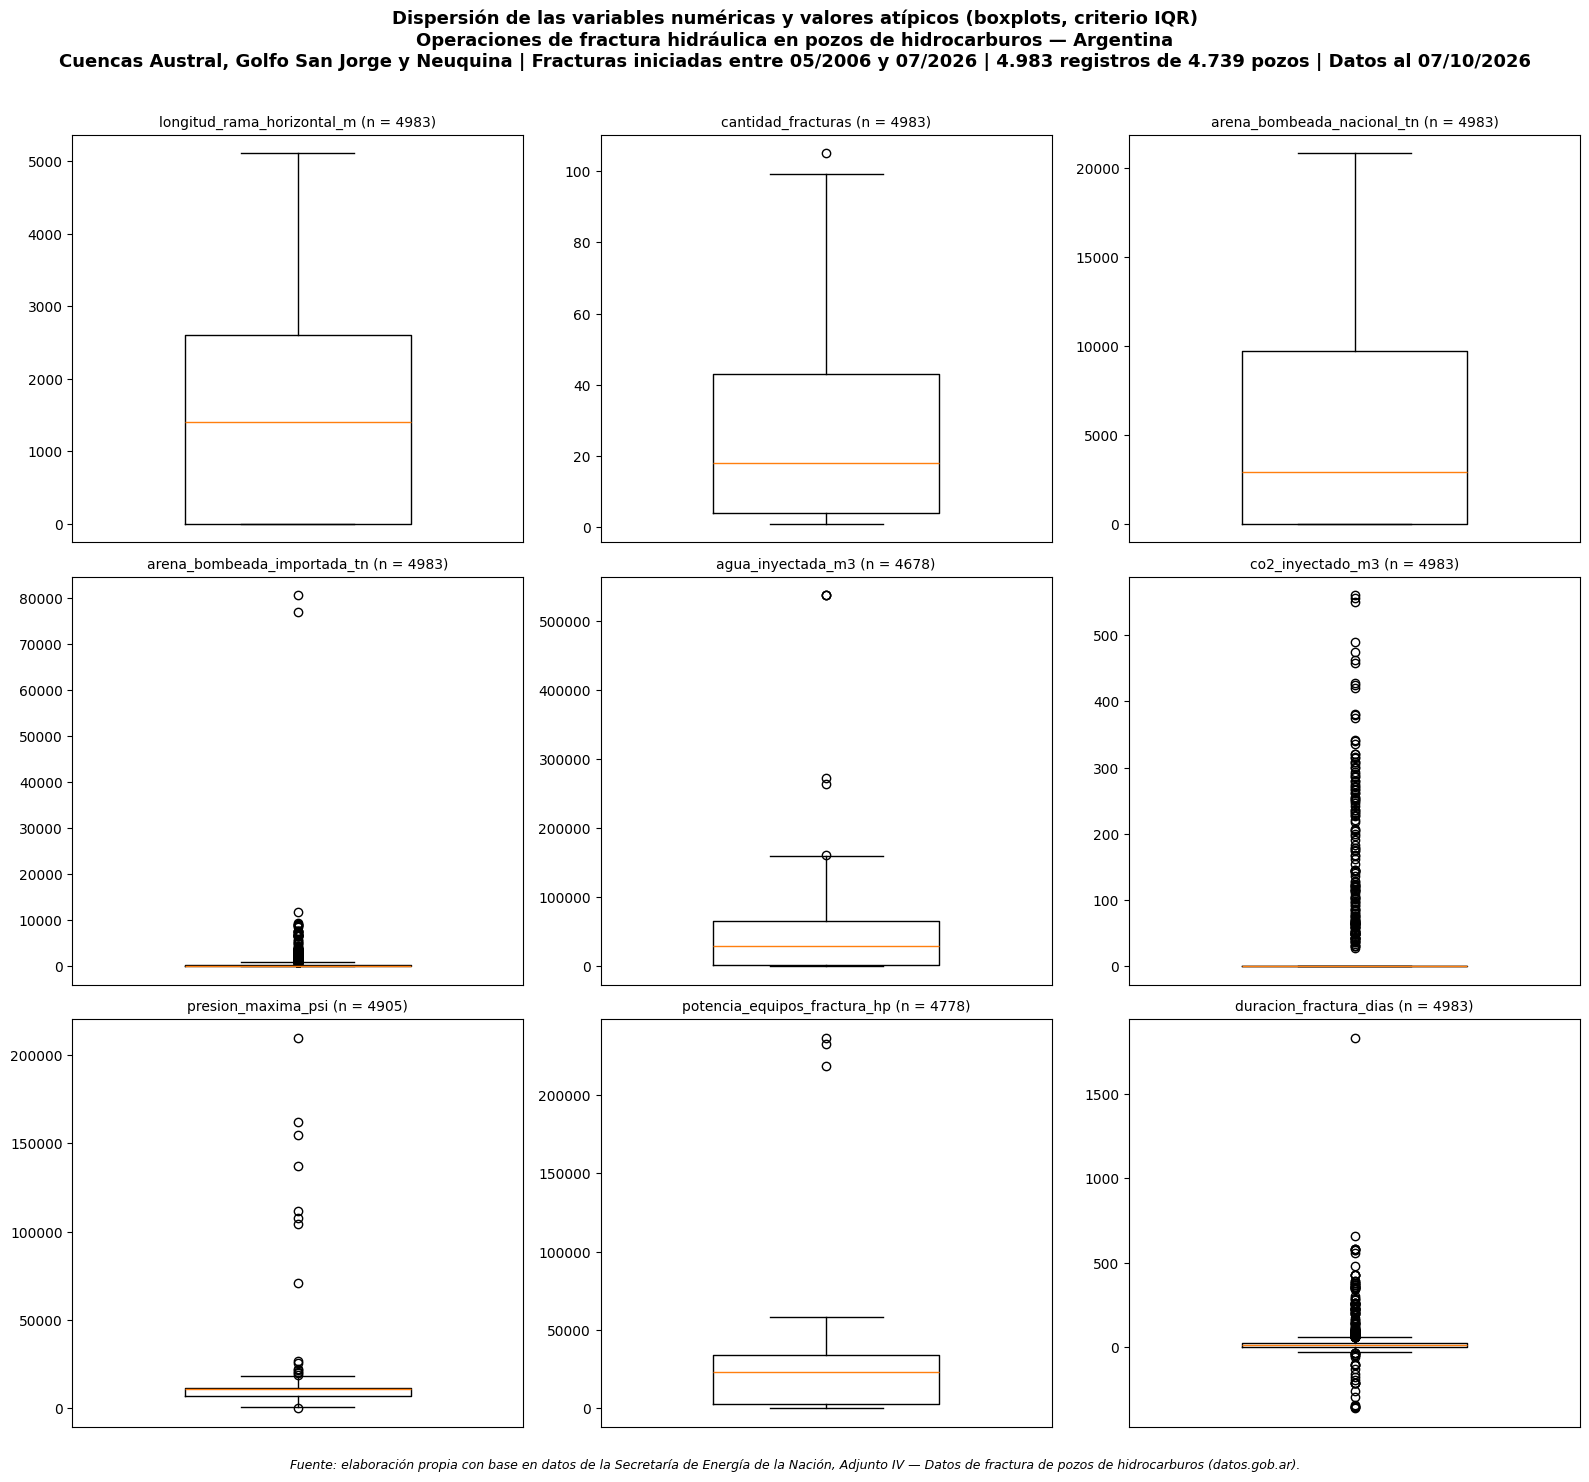

In [36]:
# @title Boxplots: dispersión y outliers
fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 4.5 * n_filas + 1.5))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    s = df_dist[col].dropna()
    ax.boxplot(s, widths=0.5)
    ax.set_title(f"{col} (n = {len(s)})", fontsize=10)
    ax.set_xticks([])

for ax in axes[len(num_cols):]:
    ax.set_visible(False)

fig.suptitle(
    "Dispersión de las variables numéricas y valores atípicos (boxplots, criterio IQR)\n"
    "Operaciones de fractura hidráulica en pozos de hidrocarburos — Argentina\n"
    "Cuencas Austral, Golfo San Jorge y Neuquina | Fracturas iniciadas entre 05/2006 y 07/2026 | "
    "4.983 registros de 4.739 pozos | Datos al 07/10/2026",
    fontsize=13, fontweight="bold",
)
fig.text(0.5, 0.005,
         "Fuente: elaboración propia con base en datos de la Secretaría de Energía de la Nación, "
         "Adjunto IV — Datos de fractura de pozos de hidrocarburos (datos.gob.ar).",
         ha="center", va="bottom", fontsize=9, style="italic")
plt.tight_layout(rect=[0, 0.025, 1, 0.97])
plt.show()

<Axes: title={'center': 'agua_inyectada_m3'}, xlabel='cuenca'>

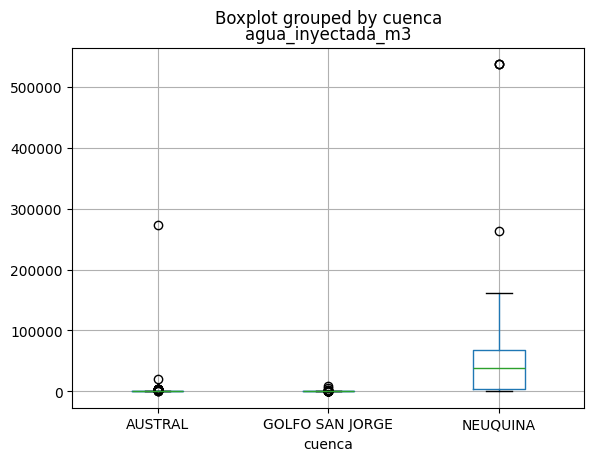

In [33]:
# @title AVERIGUAR LOS OUTLIERS!
df_datos_energia.boxplot(column="agua_inyectada_m3", by="cuenca", grid=True)

### 2.4.5 Análisis de correlación entre variables

Se construye una matriz de correlación para analizar la relación entre las variables numéricas. La correlación permite identificar:

* Variables altamente correlacionadas entre sí.
* Posibles problemas de multicolinealidad.
* Variables que pueden aportar información similar al modelo.

Si existen variables muy correlacionadas entre sí, podría ser conveniente eliminar alguna de ellas en etapas posteriores para evitar redundancia en el modelo.

In [31]:
# @title Diagramas de dispersion y calculos de correlación

# un mapa de calor maybe?
# sns.corr

# df_datos_energia.
# ACÁ HACER UNA MATRIZ DE correlación MUCHOS CONTRA MUCHOS


### 2.4.6. Relación entre variables y la variable objetivo

En esta etapa se analiza cómo se comportan las variables numéricas según la clase (Cammeo u Osmancik). Esto puede realizarse mediante:

* Boxplots por clase.
* Gráficos de dispersión.
* Comparación de medias por clase.
* Histogramas separados por clase.

Este análisis permite identificar qué variables diferencian mejor una variedad de arroz de la otra, lo cual es fundamental para la construcción del modelo de clasificación.

In [32]:
# @title Merca Merca merca

# Y ACA HACER CORRELACIOENS O GROUPBIES ESPECIFICOS ENTRE agua_inyectada_m3 CONTRA categoricas o contra otras variables continuas




## 3. Conclusiones de la fase de exploración

El archivo analizado contiene **4.910 registros y 30 variables**. La huella SHA-256 permite reconocer esta versión exacta del CSV, cuya fecha máxima de carga es el **29/09/2026**. Después de aplicar todos los criterios quedan **2.626 registros de 2.592 pozos**. La diferencia entre registros y pozos confirma que algunos pozos tienen más de una intervención; por eso `idpozo` se conserva como control y no como variable predictora.

Los filtros son secuenciales: `excluidos_en_paso` se interpreta respecto del paso anterior, no del archivo completo. Primero se retiraron 803 registros de otras cuencas y luego 376 correspondientes a reservorios convencionales dentro de la cuenca Neuquina. La mayor reducción posterior proviene de **1.071 registros sin una rama horizontal positiva**, coherente con el alcance limitado a pozos horizontales. También se excluyeron dos registros sin agua positiva y 32 con fecha de finalización anterior a la fecha de inicio.

El conjunto final representa aproximadamente el **53,5 %** del archivo original. Esta reducción no implica por sí sola mala calidad: una parte importante queda afuera por definición del alcance. En cambio, las fechas invertidas sí constituyen un problema de consistencia. Los resultados sólo describen el subconjunto retenido y no deben generalizarse a pozos convencionales, verticales u otras cuencas.